# Extra – Risk level and location
**Who:** Maram (cleaned up by Joud)  
**Input:** `food_clean.csv` (from `Task2_Cleaning.ipynb`)

Extra checks that are not part of the main feature notebooks: (1) is the risk level related to failing, and (2) what the location (Zip) columns look like.

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pandas for the table, matplotlib for the plots, scipy.stats for the tests.

In [32]:
df = pd.read_csv('food_clean.csv')
df['Inspection Date'] = pd.to_datetime(df['Inspection Date'])
df = df[df['Year'] >= 2015]   # food_clean.csv has 2010-2022, we study 2015-2022
df.shape

(126787, 22)

We read the clean file, turn the date back into a real date and keep only the study years 2015–2022 (the clean file also has 2010–2014 for the history columns).

## 1. Risk level

In [33]:
def risk_number(r):
    if r == 'Risk 1 (High)':
        return 1
    elif r == 'Risk 2 (Medium)':
        return 2
    elif r == 'Risk 3 (Low)':
        return 3
    else:
        return 0

df['Risk_Num'] = df['Risk'].apply(risk_number)
df['Risk_Num'].value_counts()

Risk_Num
1    98246
2    21563
3     6977
0        1
Name: count, dtype: int64

Risk as a number (1 = High, 2 = Medium, 3 = Low, 0 = Unknown). Risk 1 is by far the largest group (98,246 inspections), Risk 2 has 21,563 and Risk 3 has 6,977. Only 1 row is Unknown.

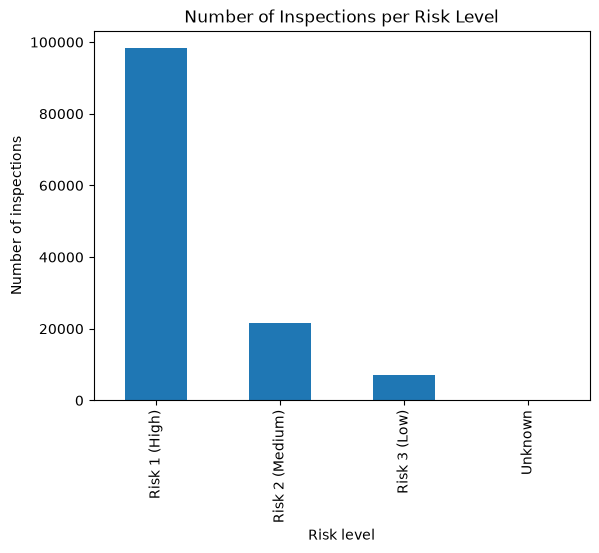

In [34]:
df['Risk'].value_counts().plot.bar()
plt.title('Number of Inspections per Risk Level')
plt.xlabel('Risk level')
plt.ylabel('Number of inspections')
plt.show()

Risk is a **category** (1, 2, 3), not a continuous number, so we use a bar chart instead of a histogram. The groups are very unbalanced: most inspections are Risk 1.

In [35]:
pd.crosstab(df['Risk'], df['Results'], normalize='index').round(3)

Results,Fail,Pass,Pass w/ Conditions
Risk,,,
Risk 1 (High),0.221,0.546,0.233
Risk 2 (Medium),0.221,0.539,0.240
Risk 3 (Low),0.265,0.524,0.211
Unknown,1.000,0.000,0.000


Share of each result per risk level. Surprisingly, **Risk 3 (Low) fails more often (about 26.5%) than Risk 1 (High, about 22%)**.

**Is the difference real or just chance?** Risk 3 has about 7,000 inspections. With that many, the standard error of a share of 26.5% is only √(0.265 × 0.735 / 7000) ≈ 0.5%, so the 95% confidence interval is about 25.5%–27.5%. Risk 1's 22% is outside this interval, so the difference is probably real. We test it formally with a chi-square test.

In [36]:
risk_fail = pd.crosstab(df['Risk'], df['Fail'])
risk_fail = risk_fail.drop('Unknown', errors='ignore')
chi2, p, dof, expected = stats.chi2_contingency(risk_fail)
print(f'Chi-square = {chi2:.2f}, df = {dof}, p-value = {p:.3e}')

Chi-square = 72.80, df = 2, p-value = 1.551e-16


**Chi-square test (Risk × Fail).**
H0: the fail rate is the same for all risk levels. H1: the fail rate is different.
Assumptions: categorical variables, independent inspections, every expected count ≥ 5 (true here, the groups are large). We remove the single "Unknown" row because its expected counts are below 5.
**Result:** chi-square = 72.80, df = 2, p ≈ 1.6 × 10⁻¹⁶. Since p < 0.05, we **reject H0**: the fail rate is different between the risk levels (Risk 1: 22.1%, Risk 2: 22.1%, Risk 3: 26.5%).

In [37]:
stats.spearmanr(df['Risk_Num'], df['Fail'])

SignificanceResult(statistic=np.float64(0.012999125648375897), pvalue=np.float64(3.678446246096782e-06))

Risk is ordinal (1 < 2 < 3) and Fail is 0/1, and neither is normal, so instead of Pearson's `corr()` we use **Spearman's** rank correlation. **Result:** Spearman's ρ = 0.013, p ≈ 3.7 × 10⁻⁶. The relationship is statistically significant but **very weak** (almost 0). With 126,787 inspections even a tiny relationship becomes significant, so the risk level alone tells us very little about whether a place will fail. Statistical significance is not the same as practical importance.

**Why might Risk 3 fail more?** Risk is about the type of food handling, not about how clean a place is, and the official dataset description says low-risk places are inspected **less often**. A hidden reason (confounding variable) could be the inspection frequency, or the type of visit. We check the type of visit next.

In [38]:
pd.crosstab(df['Risk'], df['Inspection Type'], normalize='index').round(3)[['Canvass', 'Complaint', 'License', 'Canvass Re-Inspection']]

Inspection Type,Canvass,Complaint,License,Canvass Re-Inspection
Risk,,,,
Risk 1 (High),0.526,0.101,0.112,0.152
Risk 2 (Medium),0.426,0.133,0.158,0.109
Risk 3 (Low),0.260,0.093,0.376,0.081
Unknown,0.000,0.000,1.000,0.000


Share of the main inspection types per risk level. **Result:** the type of visit is very different between the risk levels. **37.6% of Risk 3 inspections are License inspections**, compared to only 11.2% for Risk 1, while Risk 1 has many more routine Canvass inspections (52.6% vs 26.0%). License inspections happen when a new business asks for its license, and new places are often not ready yet. This is a likely **confounding variable**: Risk 3 does not fail more because it is "low risk", but because a much bigger share of its visits are license inspections. This is why the model should also use the inspection type.

## 2. Licenses with more than one risk level

In [39]:
df['License #'].nunique()

25572

There are 25,572 different license numbers in the clean data (this notebook was written before we added `Business_ID`).

In [40]:
df2 = df.groupby('License #')['Risk_Num'].value_counts().unstack()
license_with_more_than_one_risk = df2[df2.isna().sum(axis=1) < 3]
license_with_more_than_one_risk.shape

(79, 4)

79 licenses appear with more than one risk level.

In [41]:
license_with_more_than_one_risk

Risk_Num,0,1,2,3
License #,,,,
980.0,NaN,NaN,9.0,2.0
7077.0,NaN,1.0,2.0,NaN
12173.0,NaN,3.0,1.0,NaN
15956.0,NaN,11.0,1.0,NaN
22624.0,NaN,NaN,1.0,5.0
...,...,...,...,...
2657906.0,NaN,3.0,1.0,NaN
2671483.0,NaN,1.0,NaN,1.0
2745150.0,NaN,2.0,NaN,1.0


For example License # 980 has Risk 2 (9 inspections) and Risk 3 (2 inspections).

In [42]:
df[df['License #'] == 2748901][['License #','Facility Type','Risk','DBA Name','AKA Name','Inspection Date']]

,License #,Facility Type,Risk,DBA Name,AKA Name,Inspection Date
21947,2748901.0,Restaurant,Risk 3 (Low),WISHFUL GROCERS,WISHFUL GROCERS,2021-06-01
24549,2748901.0,Shared Kitchen,Risk 1 (High),CLOUD KITCHENS,CLOUD KITCHENS,2021-03-30


License # 2748901 is used by two different businesses: WISHFUL GROCERS (Restaurant, Risk 3) and CLOUD KITCHENS (Shared Kitchen, Risk 1). This is why in the cleaning we defined a business as **License # + name** (`Business_ID`).

## 3. Location (Zip)

In [43]:
df.groupby('Zip')['License #'].nunique().sort_values(ascending=False)

Zip
60647.0    1022
60614.0    1003
60611.0     896
60657.0     871
60607.0     833
           ... 
60035.0       1
60047.0       1
60706.0       1
60714.0       1
90067.0       1
Name: License #, Length: 95, dtype: int64

Number of different businesses per Zip code: the busiest Zip codes (60647, 60614, 60611) have about 900–1,000 businesses each. There are 95 Zip codes, and some have only 1 business; these are often outside Chicago.

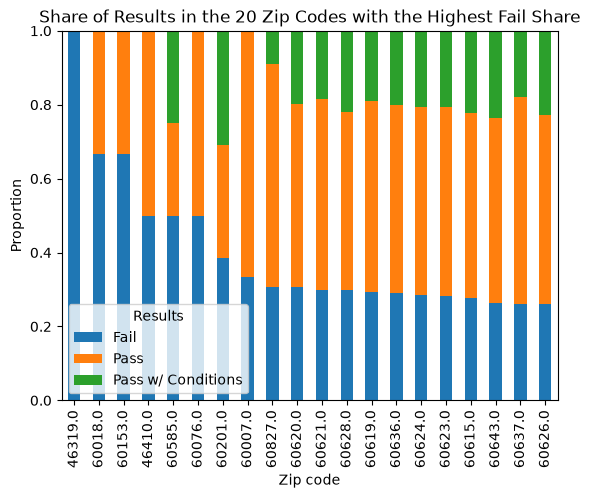

In [44]:
df.groupby('Zip')['Results'].value_counts(normalize=True).unstack().sort_values('Fail',ascending=False).head(20).plot.bar(stacked=True)
plt.title('Share of Results in the 20 Zip Codes with the Highest Fail Share')
plt.xlabel('Zip code')
plt.ylabel('Proportion')
plt.show()

The 20 Zip codes with the highest fail share. (Note: several of them have very few inspections, so their shares are not reliable.)

In [45]:
df[df['Zip']==46319]

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,...,Violations,Latitude,Longitude,Location,Business_ID,First_Seen_Date,Year,Fail,Period,Risk_Num
47154,2301197,ICE CREAM ON WHEELS,ICE CREAM ON WHEELS,2678115.0,Mobile Food Dispenser,Risk 3 (Low),2011 N GRIFFIN BLVD,GRIFFITH,IN,46319.0,...,5. PROCEDURES FOR RESPONDING TO VOMITING AND D...,NaN,NaN,NaN,2678115_ICE CREAM ON WHEELS,2019-07-16,2019,1,Post,3


Zip 46319 is GRIFFITH, Indiana: an ice-cream truck licensed in Chicago but with an address outside the city. A few rows like this are expected. If we use location in the model, we should keep only Chicago Zip codes (606xx) or group the rest into "Other".